<a href="https://colab.research.google.com/github/dhianab12-commits/machinelearningKNN/blob/main/Penelitian%20KNN%201%20Untitled13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [124]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

In [125]:
# ==========================================
# 1. INPUT DATA
# ==========================================
print("--- 1. Memuat Dataset ---")
try:
    df_balita = pd.read_csv("/content/Data_Balita_0_2_Tahun.csv", sep= None, engine='python')
    df_pola_asuh = pd.read_csv("/content/Data Kuesioner Pola Asuh.csv", sep=None, engine='python')

    # 1. Bersihkan spasi tersembunyi pada header kolom
    df_balita.columns = df_balita.columns.str.strip()
    df_pola_asuh.columns = df_pola_asuh.columns.str.strip()

    # 2. Samakan nama kolom 'Nama Responden' menjadi 'Nama' jika ada
    if 'Nama Responden' in df_pola_asuh.columns:
        df_pola_asuh.rename(columns={'Nama Responden': 'Nama'}, inplace=True)

    # ==========================================================
    # SOLUSI FINAL: GABUNGKAN PAKSA SECARA BERSEBELAHAN (CONCAT)
    # ==========================================================
    df_gabungan = pd.concat([df_balita, df_pola_asuh], axis=1)

    # Menghapus kolom duplikat (seperti 'Nama' atau 'Jenis Kelamin' yang muncul 2 kali akibat concat)
    df_gabungan = df_gabungan.loc[:, ~df_gabungan.columns.duplicated()].copy()

    print(f"Berhasil digabung paksa! Jumlah data saat ini: {len(df_gabungan)} baris")

    # 3. HAPUS KOLOM NAMA AGAR TIDAK TERBACA (ANONIM)
    if 'Nama' in df_gabungan.columns:
        df_gabungan.drop(columns=['Nama'], inplace=True)

except Exception as e:
    print("Error memuat data:", e)

--- 1. Memuat Dataset ---
Berhasil digabung paksa! Jumlah data saat ini: 567 baris


In [126]:
# ==========================================
# 2. PRA-PEMROSESAN DATA
# ==========================================
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
import pandas as pd
import numpy as np

print("\n--- 2. Pra-Pemrosesan Data ---")

# SOLUSI: Menghapus kolom duplikat akibat penggabungan 2 file CSV
df_gabungan = df_gabungan.loc[:, ~df_gabungan.columns.duplicated()].copy()

# =================================================================
# LANGKAH PENTING YANG TERLEWAT: Membuat 'Jenis_Kelamin_Encoded'
# =================================================================
# 1. Kembalikan nama kolom yang berubah akibat proses gabung (_x)
if 'Jenis Kelamin_x' in df_gabungan.columns:
    df_gabungan.rename(columns={'Jenis Kelamin_x': 'Jenis Kelamin'}, inplace=True)

# 2. Hapus duplikat Jenis Kelamin dari file kuesioner (_y) agar tidak nyampah
if 'Jenis Kelamin_y' in df_gabungan.columns:
    df_gabungan.drop(columns=['Jenis Kelamin_y'], inplace=True)

# 3. Lakukan Encoding mengubah Teks Pria/Wanita menjadi Angka
if 'Jenis Kelamin' in df_gabungan.columns:
    le = LabelEncoder()
    df_gabungan['Jenis_Kelamin_Encoded'] = le.fit_transform(df_gabungan['Jenis Kelamin'].astype(str))
else:
    print("Peringatan: Kolom 'Jenis Kelamin' asli tidak ditemukan di dataset!")

# 1. Daftar fitur
fitur_pilihan = [
    'Usia Saat Ukur',
    'Berat',
    'Tinggi',
    'Jenis_Kelamin_Encoded',
    'Total Pendidikan Ayah',
    'Total Pendidikan Ibu',
    'Total Pengeluaran Gizi Anak',
    'Total Skor (A-F)'
]

# Cek nama kolom otomatis (Pelacak Error)
kolom_asli = df_gabungan.columns.tolist()
kolom_hilang = [col for col in fitur_pilihan if col not in kolom_asli]

if kolom_hilang:
    print("DAFTAR SELURUH NAMA KOLOM ASLI DI DATASET ANDA:\n", kolom_asli)
    print("\n" + "="*50)
    raise KeyError(f"Gagal memuat data! Kolom ini ketikannya salah atau tidak ada: {kolom_hilang}")

# 2. Ambil datanya
X_mentah = df_gabungan[fitur_pilihan].copy()

# 3. Pembersihan Data Otomatis untuk Angka & Uang
kolom_angka = fitur_pilihan.copy()
kolom_angka.remove('Jenis_Kelamin_Encoded')

for col in kolom_angka:
    if col in X_mentah.columns:
        # Ubah jadi string terlebih dahulu
        X_mentah[col] = X_mentah[col].astype(str)

        # 1. Pastikan koma desimal diubah jadi titik dulu agar terbaca sistem
        X_mentah[col] = X_mentah[col].str.replace(',', '.', regex=False)

        # 2. Hapus semua huruf/teks selain angka dan titik (menggunakan regex yang aman)
        X_mentah[col] = X_mentah[col].str.replace(r'[^\d.]', '', regex=True)

        # 3. Kembalikan ke bentuk angka (jika kosong, ubah jadi NaN)
        X_mentah[col] = pd.to_numeric(X_mentah[col], errors='coerce')

# 4. Imputasi & Normalisasi
X_mentah = X_mentah.fillna(X_mentah.mean())
scaler = MinMaxScaler()
X_normalized = scaler.fit_transform(X_mentah)
X = pd.DataFrame(X_normalized, columns=fitur_pilihan)

print("Normalisasi berhasil. Jumlah fitur yang diproses:", len(X.columns))


--- 2. Pra-Pemrosesan Data ---
Normalisasi berhasil. Jumlah fitur yang diproses: 8


In [127]:
# ==========================================
# 3. PELABELAN DATA & PEMBERSIHAN TARGET
# ==========================================
print("\n--- 3. Pelabelan Data Berdasarkan Z-Score ---")

# Memastikan kolom ZS TB/U bersih dan berbentuk angka
df_gabungan['ZS TB/U'] = df_gabungan['ZS TB/U'].astype(str).str.replace(',', '.', regex=False)
df_gabungan['ZS TB/U'] = pd.to_numeric(df_gabungan['ZS TB/U'], errors='coerce')

def tentukan_label_stunting(z_score):
    if pd.isna(z_score):
        return None
    if z_score < -3.0:
        return 'Stunting'
    elif -3.0 <= z_score < -2.0:
        return 'Risiko Stunting'
    else:
        return 'Normal'

# Terapkan pelabelan ke kolom Target_Label
df_gabungan['Target_Label'] = df_gabungan['ZS TB/U'].apply(tentukan_label_stunting)

# =======================================================
# MENAMPILKAN & MENYIMPAN TABEL PELABELAN DATA MENTAH
# =======================================================
from IPython.display import display

print("\n[ Tabel Pelabelan Data Mentah (15 Baris Pertama) ]")
# Anda bebas menambahkan nama kolom lain ke dalam daftar ini jika ingin menampilkannya
kolom_tampil = ['Nama', 'Usia Saat Ukur', 'Berat', 'Tinggi', 'ZS TB/U', 'Target_Label']

# Memastikan hanya kolom yang ada yang ditampilkan agar tidak error
kolom_tersedia = [col for col in kolom_tampil if col in df_gabungan.columns]

# Menampilkan tabel interaktif di Google Colab
tabel_raw = df_gabungan[kolom_tersedia].head(15)
display(tabel_raw)

# Menyimpan seluruh data gabungan (tanpa terpotong) ke file Excel baru
try:
    nama_file_output = 'Hasil_Pelabelan_Data_Mentah.xlsx'
    df_gabungan.to_excel(nama_file_output, index=False)
    print(f"\n✅ Seluruh data (ratusan baris) beserta labelnya telah otomatis disimpan ke file: '{nama_file_output}'")
    print("   (Anda bisa mengunduhnya di menu folder sebelah kiri Google Colab)")
except Exception as e:
    print("\nGagal menyimpan file Excel:", e)

print("\n[ Distribusi Target Label Saat Ini (Sebelum SMOTE) ]")
print(df_gabungan['Target_Label'].value_counts())
print("="*50)


--- 3. Pelabelan Data Berdasarkan Z-Score ---

[ Tabel Pelabelan Data Mentah (15 Baris Pertama) ]


,Usia Saat Ukur,Berat,Tinggi,ZS TB/U,Target_Label
0,21,11.1,74.2,-2.45,Risiko Stunting
1,21,8.8,79.4,-1.51,Normal
2,19,10.9,73.7,-2.87,Risiko Stunting
3,19,9.6,68.0,-3.88,Stunting
4,17,7.7,75.0,-1.86,Normal
5,17,8.0,74.8,-2.63,Risiko Stunting
6,16,7.0,71.3,-2.78,Risiko Stunting
7,16,8.3,64.3,-3.59,Stunting
8,15,7.7,63.8,-3.69,Stunting
9,14,9.5,65.9,-3.30,Stunting



✅ Seluruh data (ratusan baris) beserta labelnya telah otomatis disimpan ke file: 'Hasil_Pelabelan_Data_Mentah.xlsx'
   (Anda bisa mengunduhnya di menu folder sebelah kiri Google Colab)

[ Distribusi Target Label Saat Ini (Sebelum SMOTE) ]
Target_Label
Risiko Stunting    189
Normal             189
Stunting           189
Name: count, dtype: int64


In [128]:
# ==========================================
# 4. PEMBAGIAN DATASET & SMOTE (YANG BENAR)
# ==========================================
print("\n--- 4. Menyeimbangkan Data dan Pembagian Latih/Uji ---")

# SOLUSI 2: Gabungkan fitur X (yang sudah dinormalisasi di Langkah 2) dengan Target Label
df_clean = pd.concat([X, df_gabungan['Target_Label'].reset_index(drop=True)], axis=1).dropna()

X_clean = df_clean[fitur_pilihan]
y_clean = df_clean['Target_Label']

minimum_kelas = y_clean.value_counts().min() if len(y_clean) > 0 else 0
print("Jumlah data terkecil pada suatu kelas:", minimum_kelas)

# Jalankan SMOTE (Kini pasti berhasil karena X sudah 100% bersih berupa angka)
if minimum_kelas > 1:
    try:
        smote = SMOTE(k_neighbors=min(3, minimum_kelas-1), random_state=42)
        X_resampled, y_resampled = smote.fit_resample(X_clean, y_clean)
        print("SMOTE Berhasil! Distribusi Kelas Setelah SMOTE:\n", y_resampled.value_counts())
    except Exception as e:
        print("SMOTE gagal:", e)
        X_resampled, y_resampled = X_clean, y_clean
else:
    X_resampled, y_resampled = X_clean, y_clean

# =======================================================
# PENGATURAN MANUAL PEMBAGIAN DATA LATIH & DATA UJI
# =======================================================
# Ubah angka desimal pada variabel 'rasio_uji' di bawah ini:
# 0.10 = 90% Latih, 10% Uji
# 0.20 = 80% Latih, 20% Uji (Standar Umum)
# 0.30 = 70% Latih, 30% Uji
rasio_uji = 0.20

print(f"\nMembagi dataset dengan proporsi: Data Latih {int((1-rasio_uji)*100)}% / Data Uji {int(rasio_uji*100)}%")

X_train, X_test, y_train, y_test = train_test_split(
    X_resampled,
    y_resampled,
    test_size=rasio_uji,
    random_state=42
)

print(f"Jumlah Data Latih: {len(X_train)} baris")
print(f"Jumlah Data Uji  : {len(X_test)} baris")


--- 4. Menyeimbangkan Data dan Pembagian Latih/Uji ---
Jumlah data terkecil pada suatu kelas: 189
SMOTE Berhasil! Distribusi Kelas Setelah SMOTE:
 Target_Label
Risiko Stunting    189
Normal             189
Stunting           189
Name: count, dtype: int64

Membagi dataset dengan proporsi: Data Latih 80% / Data Uji 20%
Jumlah Data Latih: 453 baris
Jumlah Data Uji  : 114 baris



--- 5 & 6. Optimasi Pelatihan KNN dan Prediksi ---


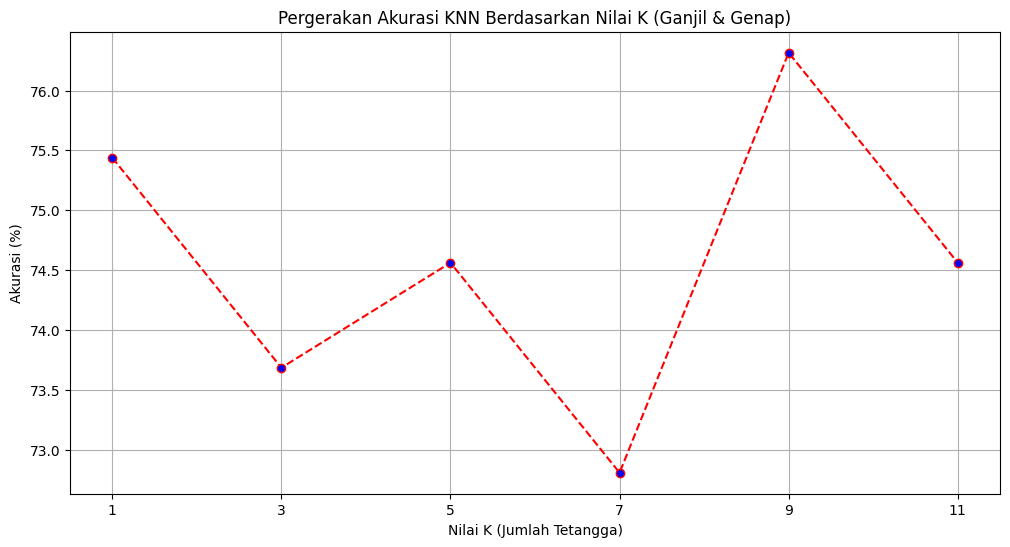


Sistem merekomendasikan K = 9 (Akurasi tertinggi: 76.32%)
Nilai K yang DIEKSEKUSI untuk model KNN adalah: K = 9


In [129]:
# ==========================================
# 5 & 6. TRAINING MODEL KNN & KLASIFIKASI
# ==========================================
print("\n--- 5 & 6. Optimasi Pelatihan KNN dan Prediksi ---")
akurasi_k = []

# UBAH DISINI: range(1, 32) akan menguji seluruh nilai K (ganjil dan genap) dari 1 hingga 31
rentang_k = range(1, 12, 2)

for k in rentang_k:
    knn = KNeighborsClassifier(n_neighbors=k, weights='distance', metric='euclidean')
    knn.fit(X_train, y_train)
    akurasi_k.append(knn.score(X_test, y_test))

# Memperbesar ukuran grafik agar titik K ganjil dan genap tidak terlalu berdesakan
plt.figure(figsize=(12, 6))
plt.plot(rentang_k, [acc * 100 for acc in akurasi_k], marker='o', linestyle='dashed', color='red', markerfacecolor='blue', markersize=6)
plt.title('Pergerakan Akurasi KNN Berdasarkan Nilai K (Ganjil & Genap)')
plt.xlabel('Nilai K (Jumlah Tetangga)')
plt.ylabel('Akurasi (%)')
plt.xticks(rentang_k) # Memunculkan semua angka K di sumbu X
plt.grid(True)
plt.show()

k_terbaik_otomatis = rentang_k[akurasi_k.index(max(akurasi_k))]
akurasi_tertinggi = max(akurasi_k) * 100
print(f"\nSistem merekomendasikan K = {k_terbaik_otomatis} (Akurasi tertinggi: {akurasi_tertinggi:.2f}%)")

print(f"Nilai K yang DIEKSEKUSI untuk model KNN adalah: K = {k_pilihan}")

# Melatih model menggunakan nilai K pilihan Anda
knn_model = KNeighborsClassifier(n_neighbors=k_pilihan, weights='distance', metric='euclidean')
knn_model.fit(X_train, y_train)
y_pred = knn_model.predict(X_test)


--- 7. Evaluasi Model (Semua Nilai K) ---

 HASIL EVALUASI UNTUK K = 1


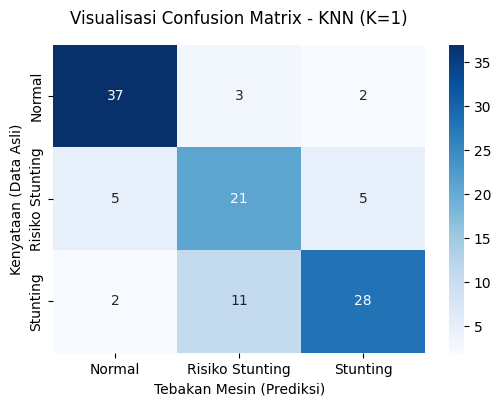

Akurasi (Accuracy) : 75.44%
Presisi (Precision): 74.70%
Recall             : 74.71%
F1-Score           : 74.46%


 HASIL EVALUASI UNTUK K = 3


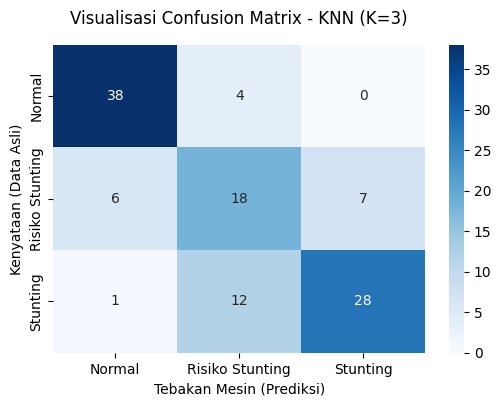

Akurasi (Accuracy) : 73.68%
Presisi (Precision): 72.46%
Recall             : 72.28%
F1-Score           : 72.14%


 HASIL EVALUASI UNTUK K = 5


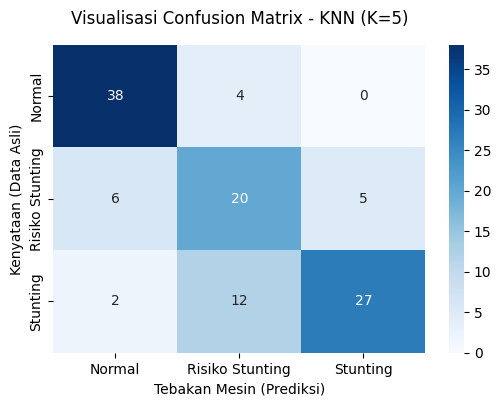

Akurasi (Accuracy) : 74.56%
Presisi (Precision): 74.18%
Recall             : 73.62%
F1-Score           : 73.35%


 HASIL EVALUASI UNTUK K = 7


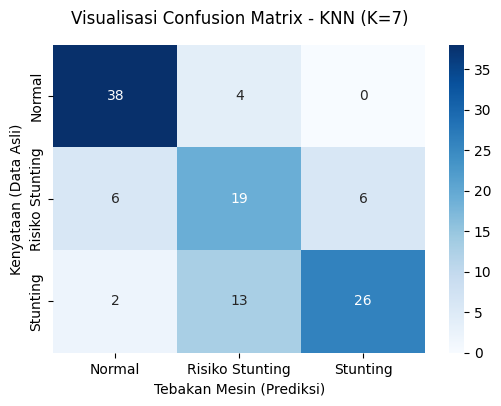

Akurasi (Accuracy) : 72.81%
Presisi (Precision): 72.21%
Recall             : 71.73%
F1-Score           : 71.44%


 HASIL EVALUASI UNTUK K = 9


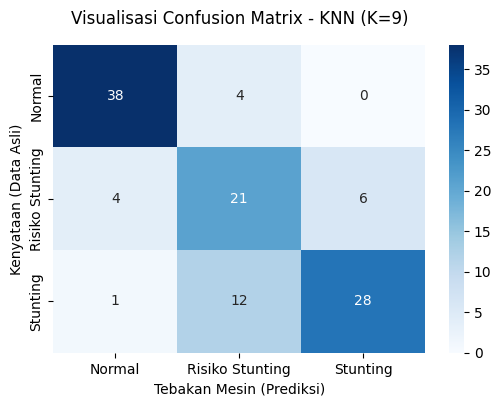

Akurasi (Accuracy) : 76.32%
Presisi (Precision): 75.83%
Recall             : 75.50%
F1-Score           : 75.28%


 HASIL EVALUASI UNTUK K = 11


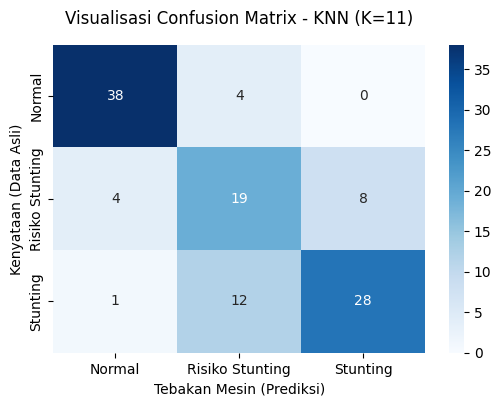

Akurasi (Accuracy) : 74.56%
Presisi (Precision): 73.48%
Recall             : 73.35%
F1-Score           : 73.24%



In [130]:
import seaborn as sns
import matplotlib.pyplot as plt

# ==========================================
# 7. HASIL EVALUASI UNTUK SEMUA NILAI K
# ==========================================
print("\n--- 7. Evaluasi Model (Semua Nilai K) ---")

# Melakukan perulangan untuk setiap angka K yang ada di 'rentang_k' (Langkah 5)
for k in rentang_k:
    print(f"\n" + "="*50)
    print(f" HASIL EVALUASI UNTUK K = {k}")
    print("="*50)

    # 1. Melatih ulang model khusus untuk K saat ini
    knn_temp = KNeighborsClassifier(n_neighbors=k, weights='distance', metric='euclidean')
    knn_temp.fit(X_train, y_train)
    y_pred_temp = knn_temp.predict(X_test)

    # 2. Menghitung Confusion Matrix
    cm = confusion_matrix(y_test, y_pred_temp)

    # 3. Menampilkan Confusion Matrix dalam Bentuk Grafik (Heatmap)
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=knn_temp.classes_,
                yticklabels=knn_temp.classes_)
    plt.title(f'Visualisasi Confusion Matrix - KNN (K={k})', pad=15)
    plt.xlabel('Tebakan Mesin (Prediksi)')
    plt.ylabel('Kenyataan (Data Asli)')
    plt.show()

    # 4. Menghitung Metrik Evaluasi
    akurasi = accuracy_score(y_test, y_pred_temp)
    presisi = precision_score(y_test, y_pred_temp, average='macro', zero_division=0)
    recall = recall_score(y_test, y_pred_temp, average='macro', zero_division=0)
    f1 = f1_score(y_test, y_pred_temp, average='macro', zero_division=0)

    print(f"Akurasi (Accuracy) : {akurasi * 100:.2f}%")
    print(f"Presisi (Precision): {presisi * 100:.2f}%")
    print(f"Recall             : {recall * 100:.2f}%")
    print(f"F1-Score           : {f1 * 100:.2f}%\n")

    # (Opsional) Hapus tanda '#' di bawah ini jika ingin melihat laporan klasifikasi lengkap per K
    # print("Detail Laporan Klasifikasi:")
    # print(classification_report(y_test, y_pred_temp, zero_division=0))


--- 8. Hasil 5-Fold Cross Validation (Semua K) ---
K =  1 | Rata-rata Akurasi CV: 75.15%
K =  3 | Rata-rata Akurasi CV: 77.95%
K =  5 | Rata-rata Akurasi CV: 74.78%
K =  7 | Rata-rata Akurasi CV: 74.25%
K =  9 | Rata-rata Akurasi CV: 73.55%
K = 11 | Rata-rata Akurasi CV: 73.55%


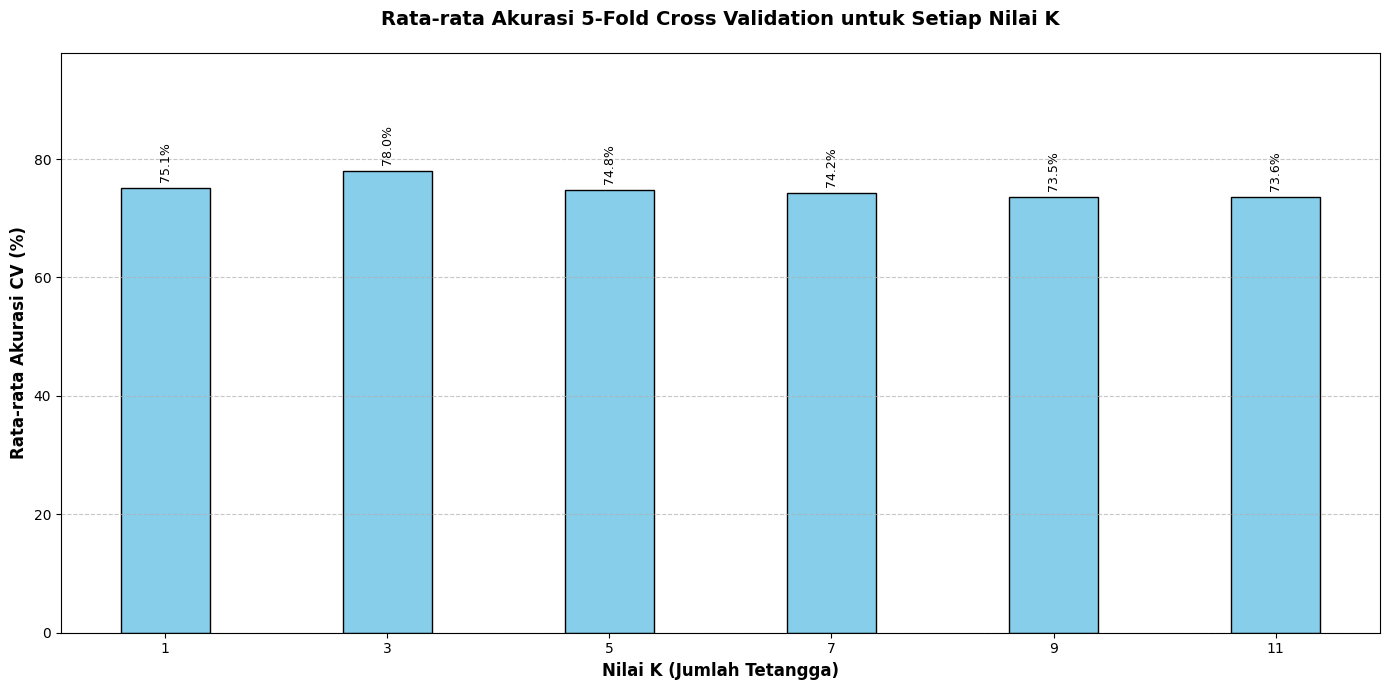


Berdasarkan pengujian 5-Fold Cross Validation, nilai K paling tangguh (optimal) adalah K = 3 dengan akurasi 77.95%


In [131]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier

# ==========================================
# 7. ANALISIS 5-FOLD CROSS VALIDATION (SEMUA K)
# ==========================================
print("\n" + "="*50)
print("--- 8. Hasil 5-Fold Cross Validation (Semua K) ---")
print("="*50)

rata_rata_cv = []

# Melakukan perulangan untuk setiap nilai K
for k in rentang_k:
    knn_cv = KNeighborsClassifier(n_neighbors=k, weights='distance', metric='euclidean')

    # Menjalankan 5-Fold Cross Validation
    cv_scores = cross_val_score(knn_cv, X_resampled, y_resampled, cv=5, scoring='accuracy')

    # Menyimpan rata-rata akurasi (dalam bentuk persentase)
    rata_rata_akurasi = cv_scores.mean() * 100
    rata_rata_cv.append(rata_rata_akurasi)

    print(f"K = {k:2d} | Rata-rata Akurasi CV: {rata_rata_akurasi:.2f}%")

# =======================================================
# MEMBUAT GRAFIK DIAGRAM BATANG (BAR CHART)
# =======================================================
plt.figure(figsize=(14, 7))

# Membuat diagram batang
bars = plt.bar(rentang_k, rata_rata_cv, color='skyblue', edgecolor='black')

# Menambahkan angka persentase di atas setiap batang agar mudah dibaca
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 1, f'{yval:.1f}%',
             ha='center', va='bottom', fontsize=9, rotation=90)

# Pengaturan label dan judul grafik
plt.title('Rata-rata Akurasi 5-Fold Cross Validation untuk Setiap Nilai K', fontsize=14, pad=20, fontweight='bold')
plt.xlabel('Nilai K (Jumlah Tetangga)', fontsize=12, fontweight='bold')
plt.ylabel('Rata-rata Akurasi CV (%)', fontsize=12, fontweight='bold')

# Menampilkan semua angka K di sumbu X
plt.xticks(rentang_k)

# Memberikan ruang tambahan di atas grafik agar teks persentase tidak terpotong
plt.ylim(0, max(rata_rata_cv) + 20)

# Menambahkan garis bantu horizontal (grid)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# Kesimpulan K terbaik berdasarkan Cross Validation
k_cv_terbaik = rentang_k[np.argmax(rata_rata_cv)]
akurasi_cv_tertinggi = max(rata_rata_cv)
print(f"\nBerdasarkan pengujian 5-Fold Cross Validation, nilai K paling tangguh (optimal) adalah K = {k_cv_terbaik} dengan akurasi {akurasi_cv_tertinggi:.2f}%")

In [132]:
# ==========================================
# 8. OUTPUT SISTEM (PREDIKSI DARI DATA UJI ASLI)
# ==========================================
from IPython.display import display

print("\n--- 8. Simulasi Output Sistem (Mengambil 5 Data Pertama dari Data Uji Asli) ---")

# 1. Mengambil 5 index pertama dari data uji yang sudah dibagi sebelumnya (test_idx)
lima_index_uji = test_idx[:5]

# 2. Mengambil data asli langsung dari dataframe master (sebelum dinormalisasi)
# Ini memastikan angka (Usia, Berat, Tinggi, Pendidikan, dll) tampil dengan nilai aslinya yang benar
tabel_tampil = df_original.loc[lima_index_uji].copy()

# 3. Mengambil 5 baris pertama dari X_test untuk diprediksi oleh model KNN
data_uji_5_baris = X_test.head(5)
hasil_prediksi = knn_model.predict(data_uji_5_baris)

# 4. Merapikan tampilan tabel dengan menyisipkan nomor sampel uji
tabel_tampil.insert(0, 'Sampel Uji', ['Data Uji 1', 'Data Uji 2', 'Data Uji 3', 'Data Uji 4', 'Data Uji 5'])

# 5. Menambahkan kolom hasil tebakan mesin (PREDIKSI) di ujung kanan tabel
tabel_tampil['Status Gizi (PREDIKSI)'] = [status.upper() for status in hasil_prediksi]

# 6. Menampilkan hasil dalam bentuk tabel interaktif yang rapi
print("\n[ Tabel Komparasi 5 Data Uji Asli dan Hasil Prediksinya ]")
display(tabel_tampil)


--- 8. Simulasi Output Sistem (Mengambil 5 Data Pertama dari Data Uji Asli) ---

[ Tabel Komparasi 5 Data Uji Asli dan Hasil Prediksinya ]


,Sampel Uji,Nama;Jenis Kelamin;Usia Saat Ukur;Berat;Tinggi;BB/U;ZS BB/U;TB/U;ZS TB/U;BB/TB;ZS BB/TB;Label_Stunting,Status Gizi (PREDIKSI)
540,Data Uji 1,ABDIEL BRIANDO DEJESUS;Laki-Laki;20;10;81.5;No...,NORMAL
525,Data Uji 2,WAHID AHMAD FIRDAUS;Laki-Laki;5;7.2;63.7;Norma...,NORMAL
234,Data Uji 3,GERAL AMARAL;Laki-Laki;7;7.8;66.3;Normal;-0.85...,RISIKO STUNTING
526,Data Uji 4,MORGALIFA C. MELLO;Perempuan;5;6.5;63;Normal;-...,NORMAL
490,Data Uji 5,SALITA SANAM;Perempuan;8;8;68.1;Normal;-0.16;N...,NORMAL
